In [1]:
import numpy as np
import numpy.ma as ma
from netCDF4 import Dataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors
from matplotlib.colors import BoundaryNorm

import matplotlib.gridspec as gridspec
import xarray as xr
from statsmodels.tsa.arima_model import ARMA
from statsmodels.tsa.arima_process import ArmaProcess
import string

import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs
from scipy import signal
from scipy.signal import periodogram
import eofs
import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation

from iris.analysis import stats
from iris.analysis import maths

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


#### Open age

In [2]:
### Upload PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = [ 'ACCESS-ESM1-5', 'KCM', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['agessc_Omon_ACCESS-ESM1-5_piControl_r1i1p1f1_gn_100yr_mean_reg_360x385_intlevel.nc',
                   'H0K_ym_6401_6500.codeAGE_100yr_mean_reg_360x385_intlevel.nc',
                   'age.NBF1850OC_f19_tn11_02.micom.hy.1600-1699_regridded_100yr_mean_intlevel.nc',
                   'agessc_Omon_NorESM2-LM_piControl_r1i1p1f1_gr_200101-210012_100yr_mean_regridded_360x385_intlevel.nc']

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'agessc'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'idlagelvl'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'agessc')]

PI_models = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path2+names_models_pi[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    PI_models.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'areacello', referenced by netCDF variable 'agessc'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'volcello', referenced by netCDF variable 'agessc'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: 

In [3]:
### Upload LIG
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = [ 'ACCESS-ESM1-5', 'KCM', 'NorESM1-F', 'NorESM2-LM']
names_models_lig = ['agessc_Omon_ACCESS-ESM1-5_lig127k_r1i1p1f1_gn_100yr_mean_reg_360x385_intlevel.nc',
                   'E7C_ym_4901_5000.codeAGE_100yr_mean_reg_360x385_intlevel.nc',
                   'age.NBF1850OC_f19_tn11_01_127ka.micom.hy.1600-1699_regridded_100yr_mean_intlevel.nc',
                   'agessc_Omon_NorESM2-LM_lig127k_r1i1p1f1_gr_210101-220012_100yr_mean_regridded_360x385_intlevel.nc']

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'age_global'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'idlagelvl'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'agessc')]

LIG_models = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path2+names_models_lig[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_lig[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    LIG_models.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

#### Open oxygen

In [4]:
## PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'
models = [ 'ACCESS-ESM1-5', 'KCM', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['o2_Omon_ACCESS-ESM1-5_pi_100ymean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_KCM_piControl_r1i1p1f1_6401_6500_100yr_mean_intlevel.nc',
                   'o2_Oyr_NorESM1-F_piControl_r1i1p1f1_gr_1601-1700_100yr_mean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_NorESM2-LM_piControl_r1i1p1f1_gr_2001-2100_regridded_100yr_mean_intlevel.nc',]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2')]

PI_models_o2 = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    PI_models_o2.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'areacello', referenced by netCDF variable 'o2'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'volcello', referenced by netCDF variable 'o2'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversi

In [6]:
### LIG
path = '/nfs/hera1/ee22kvcs/PMIP4/'
models = [ 'ACCESS-ESM1-5', 'KCM', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['o2_Omon_ACCESS-ESM1-5_lig_100ymean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_KCM_lig127k_r1i1p1f1_4901_5000_100yr_mean_intlevel.nc',
                   'o2_Oyr_NorESM1-F_lig127k_r1i1p1f1_gr_1601-1700_100yr_mean_regridded_360x385_intlevel.nc',
                   'o2_Oyr_NorESM2-LM_lig127k_r1i1p1f1_gr_2101-2200_100yr_mean_regridded_360x385_intlevel.nc',]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2_raw'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'o2')]

LIG_models_o2 = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    LIG_models_o2.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

#### Open masks

In [7]:
## Models
path_mask_atl = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Atlantic_ocean_NorESM2-LM.nc'
path_mask_pac = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Pacific_ocean_NorESM2-LM.nc'
path_mask_ind = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Indian_ocean_NorESM2-LM.nc'
masks = iris.Constraint(cube_func=lambda cube: cube.var_name == 'mask')
## Open
atlantic_mask = iris.load_cube(path_mask_atl, masks)
pacific_mask = iris.load_cube(path_mask_pac, masks)
indian_mask = iris.load_cube(path_mask_ind, masks)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [8]:
def broadcast_masks_to_models(models, atlantic_mask, pacific_mask, indian_mask):
    "Input: lists iof iris cubes.Output: dictionary of broadcasted mask cubes by basin"
    broadcasted_masks = {"atlantic": [], "pacific": [], "indian": []}
    
    for model in models:
        shape = model.shape  # (depth, lat, lon) or similar
        
        # Broadcast each mask
        atl_broadcast = np.broadcast_to(atlantic_mask.data, shape)
        pac_broadcast = np.broadcast_to(pacific_mask.data, shape)
        ind_broadcast = np.broadcast_to(indian_mask.data, shape)
        
        # Replace NaNs with masked values
        atl_masked = np.ma.masked_invalid(atl_broadcast)
        pac_masked = np.ma.masked_invalid(pac_broadcast)
        ind_masked = np.ma.masked_invalid(ind_broadcast)
        
        # Create cubes with the same metadata as the model
        broadcasted_masks["atlantic"].append(model.copy(data=atl_masked))
        broadcasted_masks["pacific"].append(model.copy(data=pac_masked))
        broadcasted_masks["indian"].append(model.copy(data=ind_masked))
    
    return broadcasted_masks

In [9]:
## Use masks for O2
masks_LIG = broadcast_masks_to_models(LIG_models_o2, atlantic_mask, pacific_mask, indian_mask)
masks_PI = broadcast_masks_to_models(PI_models_o2, atlantic_mask, pacific_mask, indian_mask)

In [10]:
## Use masks for Age
masks_LIG_age = broadcast_masks_to_models(LIG_models, atlantic_mask, pacific_mask, indian_mask)
masks_PI_age = broadcast_masks_to_models(PI_models, atlantic_mask, pacific_mask, indian_mask)

### Setup the data

#### Oxygen

In [11]:
### PI data by basin
atlantic_masked_PI_models_o2 = [m * mask for m, mask in zip(PI_models_o2, masks_PI["atlantic"])]
indian_masked_PI_models_o2 = [m * mask for m, mask in zip(PI_models_o2, masks_PI["indian"])]
pacific_masked_PI_models_o2 = [m * mask for m, mask in zip(PI_models_o2, masks_PI["pacific"])]
### LIG data
atlantic_masked_LIG_models_o2 = [m * mask for m, mask in zip(LIG_models_o2, masks_LIG["atlantic"])]
indian_masked_LIG_models_o2 = [m * mask for m, mask in zip(LIG_models_o2, masks_LIG["indian"])]
pacific_masked_LIG_models_o2 = [m * mask for m, mask in zip(LIG_models_o2, masks_LIG["pacific"])]

In [12]:
#### PI zonal means
atl_an_zmean_o2_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_PI_models_o2]
ind_an_zmean_o2_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_PI_models_o2]
pac_an_zmean_o2_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_PI_models_o2]
#### LIG zonal means
atl_an_zmean_o2_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_LIG_models_o2]
ind_an_zmean_o2_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_LIG_models_o2]
pac_an_zmean_o2_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_LIG_models_o2]

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:1017: UserWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'longitude'.
  warnings.warn(msg.format(self.name()))


In [13]:
### Differences O2
factors = [1, 1e6, 1e3, 1e3]

dif_o2_atl = []
dif_o2_pac = []
dif_o2_ind = []

for i in range (np.size(atl_an_zmean_o2_PI)):
    multiply = factors[i]
    dif_atl = (atl_an_zmean_o2_LIG[i].data - atl_an_zmean_o2_PI[i].data) * multiply
    dif_pac = (pac_an_zmean_o2_LIG[i].data - pac_an_zmean_o2_PI[i].data) * multiply
    dif_ind = (ind_an_zmean_o2_LIG[i].data - ind_an_zmean_o2_PI[i].data) * multiply

    dif_atl_cube = atl_an_zmean_o2_PI[i].copy(data = dif_atl)
    dif_pac_cube = pac_an_zmean_o2_PI[i].copy(data = dif_pac)
    dif_ind_cube = ind_an_zmean_o2_PI[i].copy(data = dif_ind)
    
    dif_o2_atl.append(dif_atl_cube)
    dif_o2_pac.append(dif_pac_cube)
    dif_o2_ind.append(dif_ind_cube)

/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3337: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _data[indx] = dval
/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3340: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _mask[indx] = mval


#### Age

In [14]:
### PI data by basin
atlantic_masked_PI_models_age = [m * mask for m, mask in zip(PI_models, masks_PI_age["atlantic"])]
indian_masked_PI_models_age = [m * mask for m, mask in zip(PI_models, masks_PI_age["indian"])]
pacific_masked_PI_models_age = [m * mask for m, mask in zip(PI_models, masks_PI_age["pacific"])]
### LIG data
atlantic_masked_LIG_models_age = [m * mask for m, mask in zip(LIG_models, masks_LIG_age["atlantic"])]
indian_masked_LIG_models_age = [m * mask for m, mask in zip(LIG_models, masks_LIG_age["indian"])]
pacific_masked_LIG_models_age = [m * mask for m, mask in zip(LIG_models, masks_LIG_age["pacific"])]

In [15]:
#### Zonal means
#### PI zonal means
atl_an_zmean_age_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_PI_models_age]
ind_an_zmean_age_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_PI_models_age]
pac_an_zmean_age_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_PI_models_age]

#### LIG zonal means
atl_an_zmean_age_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_LIG_models_age]
ind_an_zmean_age_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_LIG_models_age]
pac_an_zmean_age_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_LIG_models_age]

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:1017: UserWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'longitude'.
  warnings.warn(msg.format(self.name()))


In [16]:
#### Differences of age zmeans
dif_atl_age = []
dif_pac_age = []
dif_ind_age = []

for i in range(np.size(atl_an_zmean_age_PI)):
    dif_atl_array = atl_an_zmean_age_LIG[i].data - atl_an_zmean_age_PI[i].data
    dif_pac_array = pac_an_zmean_age_LIG[i].data - pac_an_zmean_age_PI[i].data
    dif_ind_array = ind_an_zmean_age_LIG[i].data - ind_an_zmean_age_PI[i].data
    
    dif_atl_cube = atl_an_zmean_age_PI[i].copy(data=dif_atl_array)
    dif_pac_cube = pac_an_zmean_age_PI[i].copy(data=dif_pac_array)
    dif_ind_cube = ind_an_zmean_age_PI[i].copy(data=dif_ind_array)
    
    dif_atl_age.append(dif_atl_cube)
    dif_pac_age.append(dif_pac_cube)
    dif_ind_age.append(dif_ind_cube)

/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3337: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _data[indx] = dval
/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3340: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _mask[indx] = mval


### Plot

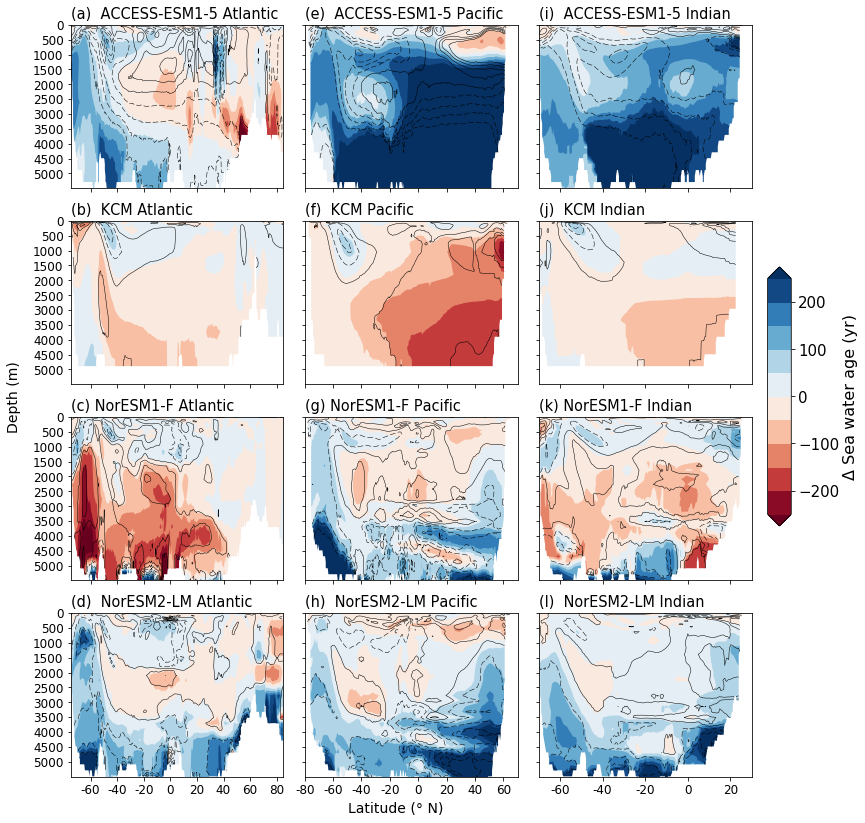

In [17]:
fig = plt.figure(figsize=(11, 12))

n_models = 4
n_basins = 3

axes = np.empty((n_models, n_basins), dtype=object)
for i in range(n_models):
    for j in range(n_basins):
        idx = i * n_basins + j + 1
        axes[i, j] = fig.add_subplot(n_models, n_basins, idx)

model_names = [' ACCESS-ESM1-5', ' KCM', 'NorESM1-F', ' NorESM2-LM']
basin_names = ['Atlantic', 'Pacific', 'Indian']
simulations_list = [dif_atl_age, dif_pac_age, dif_ind_age]
o2_simulations_list = [dif_o2_atl, dif_o2_pac, dif_o2_ind]
depth = ['depth', 'plev', 'depth', 'depth']

# Letters: column 1 = a-g, column 2 = h-n, column 3 = o-u
letters = list(string.ascii_lowercase)
letter_cols = [letters[0:4], letters[4:8], letters[8:12]]

levels = np.arange(-250, 250+50, 50)
levels2 = np.arange(-40, 40+10, 10)

im = None

for j, simulations in enumerate(simulations_list):
    o2_simulations = o2_simulations_list[j]   # O2 for the same basin
    
    for n in range(n_models):
        ax = axes[n, j]
        ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)
        ax.set_ylim(0, 5500)
        
        ax.set_yticks(np.arange(0, 5000+500, 500))
        if j == 0:
            ax.tick_params(axis='y', labelsize=12)
        else:
            ax.set_yticklabels([])

        if n == n_models - 1:
            ax.set_xticklabels(ax.get_xticks(), fontsize=12)
        else:
            ax.set_xticklabels([])
        #----------------------------------------------
        if j == 0:
            ax.set_xlim(-75, 85)
        elif j == 1:
            ax.set_xlim(-80, 70)
        else:
            ax.set_xlim(-70, 30)

        letter = letter_cols[j][n]
        title_str = "(" + letter + ") " + model_names[n] + " " + basin_names[j]
        ax.set_title(title_str, fontsize=14.5, loc='left')
        #------------------------------------------------
        im = iplt.contourf(simulations[n], coords=['latitude', depth[n]], axes=ax, levels=levels, cmap='RdBu', extend='both')
        im2 = iplt.contour(o2_simulations[n], coords=['latitude', depth[n]], axes=ax, colors='k', levels=levels2, linewidths=0.5)

        if n == 1:
            ax.invert_yaxis()

# shared colorbar
fig.subplots_adjust(left=0.12, right=0.88, top=0.95, bottom=0.05, wspace=0.1, hspace=0.1)
cbar_ax = fig.add_axes([0.97, 0.35, 0.03, 0.3])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.ax.set_ylabel('Δ Sea water age (yr)', size=16)
cbar.ax.tick_params(labelsize=15)

# Shared axis labels
fig.text(0.01, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=14)
fig.text(0.5, 0.018, 'Latitude (° N)', ha='center', fontsize=14)

plt.subplots_adjust(left=0.09, bottom=0.06, right=0.95, top=0.93, wspace=0.1, hspace=0.2)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Age_O2_zonally_mean_diff_3basins_v3.png', bbox_inches='tight', dpi=300, format='png')
plt.show()

### MMM

In [18]:
### MMM of Difference of O2
MMM_dif_atl_o2 = sum([dif_o2_atl[i].data for i in range(np.size(dif_o2_atl))])/4
MMM_dif_pac_o2 = sum([dif_o2_pac[i].data for i in range(np.size(dif_o2_pac))])/4
MMM_dif_ind_o2 = sum([dif_o2_ind[i].data for i in range(np.size(dif_o2_ind))])/4
## Convert arrays to iris cubes
MMM_dif_atl_o2_cube = dif_o2_atl[0].copy(data = MMM_dif_atl_o2)
MMM_dif_pac_o2_cube = dif_o2_pac[0].copy(data = MMM_dif_pac_o2)
MMM_dif_ind_o2_cube = dif_o2_ind[0].copy(data = MMM_dif_ind_o2)

In [19]:
#### MMM of Difference of seawater age
MMM_dif_atl = sum([dif_atl_age[i].data for i in range(np.size(dif_atl_age))])/4
MMM_dif_pac = sum([dif_pac_age[i].data for i in range(np.size(dif_pac_age))])/4
MMM_dif_ind = sum([dif_ind_age[i].data for i in range(np.size(dif_ind_age))])/4
## Convert arrays to iris cubes
MMM_dif_atl_cube = dif_atl_age[0].copy(data = MMM_dif_atl)
MMM_dif_pac_cube = dif_pac_age[0].copy(data = MMM_dif_pac)
MMM_dif_ind_cube = dif_ind_age[0].copy(data = MMM_dif_ind)

#### Spread

In [20]:
def calculate_spread(dif_list, threshold=0, min_models=3):
    "Spread of the difference, where min_models agree on change above or below a threshold"
    # Model differences in a 3D array (models, lat, depth)
    model_difs = np.array([dif_list[i].data for i in np.arange(np.size(dif_atl_age))])

    # Count models exceeding thresholds
    positive_count = np.sum(model_difs > threshold, axis=0)
    negative_count = np.sum(model_difs < -threshold, axis=0)

    # Agreement mask
    agreement_mask = (positive_count >= min_models) | (negative_count >= min_models)

    # Non-agreement mask
    non_agreement_mask = ~agreement_mask

    return agreement_mask, non_agreement_mask

In [21]:
agreement_atl_thresh, non_agreement_atl_thresh = calculate_spread(dif_atl_age, threshold=0)
agreement_ind_thresh, non_agreement_ind_thresh = calculate_spread(dif_ind_age, threshold=0)
agreement_pac_thresh, non_agreement_pac_thresh = calculate_spread(dif_pac_age, threshold=0)

#### Plot

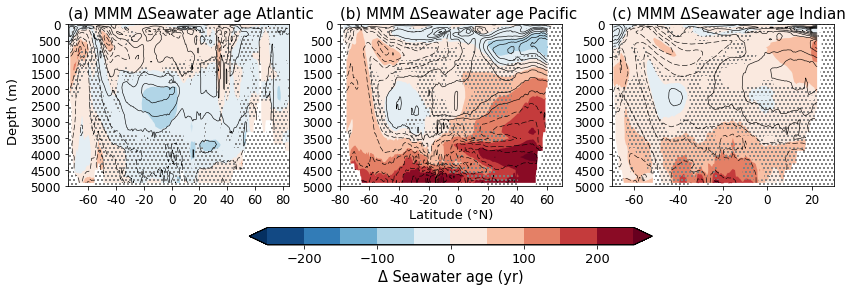

In [22]:
fig = plt.figure(figsize=(14, 3))
axes = []

# Create subplots with custom positioning
ax1 = fig.add_axes([0.05, 0.15, 0.22, 0.75])  # [left, bottom, width, height]
ax2 = fig.add_axes([0.32, 0.15, 0.22, 0.75])
ax3 = fig.add_axes([0.59, 0.15, 0.22, 0.75])

axes = [ax1, ax2, ax3]

titles = ['(a) MMM ΔSeawater age Atlantic', '(b) MMM ΔSeawater age Pacific', '(c) MMM ΔSeawater age Indian']
simulations = [MMM_dif_atl_cube, MMM_dif_pac_cube, MMM_dif_ind_cube]
simulations_o2 = [MMM_dif_atl_o2_cube, MMM_dif_pac_o2_cube, MMM_dif_ind_o2_cube]
depth = ['depth', 'depth', 'depth']
spread = [MMM_dif_atl_cube, MMM_dif_pac_cube, MMM_dif_ind_cube]
non_agreement_list = [non_agreement_atl_thresh, non_agreement_pac_thresh, non_agreement_ind_thresh]


for (ax, t, n) in zip(axes, titles, range(np.size(simulations))):
    ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.set_yticks(np.arange(0, 5000+500, 500))
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_ylim(0, 5000)
    #ax.set_xlim(-80, 80)
    if n == 2: ## Indian
        ax.set_xlim(-70, 30)
    elif n == 1: ## Pacific
        ax.set_xlim(-80, 70)
    else: ## Atlantic
        ax.set_xlim(-75, 85)
    
    ax.set_title(t, fontsize=15, loc='left')
    
    levels = np.arange(-250,250+50,50)
    o2_levels_diff = np.arange(-40, 40, 5) #[-50,-45,-40,-30,-10,-5,0,5,10,30,40,45]
    
    im = iplt.contourf(simulations[n], coords=['latitude', depth[n]], levels = levels, axes = ax, cmap = 'RdBu_r', extend = 'both')
    im2 = iplt.contour(simulations_o2[n], coords=['latitude', depth[n]], levels=o2_levels_diff, colors='k', linewidths=0.6, axes=ax)

    # Colorbar
    cbar_ax = fig.add_axes([0.23, -0.12, 0.40, 0.08])  # [left, bottom, width, height]
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.ax.set_xlabel('Δ Seawater age (yr)', size=14.5)
    cbar.ax.tick_params(labelsize=13)
    # Hatching
    mpl.rcParams['hatch.color'] = 'gray'
    for i in range(np.size(spread)):
        ax.contourf(spread[i].coord('latitude').points, spread[i].coord('depth').points,
                    non_agreement_list[n],  # use per-basin agreement mask
                    levels=[0.5, 1.5], hatches=['...'], alpha=0, colors='none')
        
fig.text(-0.01, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=13)
fig.text(0.43, 0.001, 'Latitude (°N)', ha='center', fontsize=13)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/age_o2_MMM_zonally_mean_by_basin_v2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()